<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/HybridQCNN_MalwareImage_Rani2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical CNN (HQCCNN) vs transfer learning for malware-family images: Rani and Mouleeswaran (2024) step by step

This notebook re-implements, runs and checks the method of

> Soja Rani S and Mouleeswaran,
> "Image Based Malware Detection Using Transfer Learning and Hybrid Quantum Machine Learning Models",
> *Nanotechnology Perceptions* 20 (S6), 1046-1060, 2024. https://doi.org/10.62441/nano-ntp.vi.1527

The paper turns Windows malware executables into grey-scale pictures (one pixel per byte, "byte plots"), and asks which of four image classifiers
recognises the **25 malware families of the Malimg benchmark** best: a **standard CNN**, **VGG16** and **ResNet** used as *transfer-learning*
networks (ImageNet weights), and a **Hybrid Quantum-Classical Convolutional Neural Network (HQCCNN)** whose convolution and pooling layers are
parameterised quantum circuits simulated with PennyLane and trained with PyTorch. The authors report about 97 % accuracy for all four, with the
hybrid model working on much smaller images (25 x 25 instead of 100 x 100).

**What the notebook does.**
1. Streams the real **Malimg** images from the public Hugging Face mirror `yanjunxi/Malimg` (no gating, no token needed; the zip files are read with HTTP range
   requests so no 1 GB archive is ever stored), keeps a family-capped sample and caches 100 x 100 byte-plots.
2. Shows the data (class counts, real images, 2-D projections coloured by the true family).
3. Implements the quantum convolution + pooling circuit, **draws the circuit that is executed**, and proves with an assertion that the fast exact
   simulator used for training equals the real PennyLane `QNode`.
4. Trains the paper's four models (standard CNN, VGG16 and ResNet transfer learning, hybrid QCNN) with the paper's batch size and epochs, plus
   **classical controls on exactly the same inputs** (a classical 2 x 2 convolution in place of the quantum layer, the same CNN on 25 x 25 images,
   random forest and RBF-SVM), over several random splits.
5. Re-computes the paper's Table 4 (accuracy, precision, recall, F1, AUC) and prints it next to the paper's numbers with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned packages if needed; if Colab asks you to
restart the session, do so and run all again. No GPU, no Hugging Face token and no IBM account are needed. The ImageNet weights of VGG16 (about 528 MB) and
ResNet-18 (45 MB) are downloaded by torchvision on first use.

**Runtime.** `FAST_MODE = True`: about 5 to 10 minutes on a laptop CPU (a small family-capped sample, 1 split, few epochs). `FAST_MODE = False`: the paper's batch size and epochs on a
larger sample, 3 splits; the wall-clock time of the run that produced the outputs below is printed in the last cell. The committed outputs come from this full run: about 114 minutes on a heavily shared laptop CPU with one thread (about 23 min for the VGG16 / ResNet feature extraction, about 55 min for the hybrid model and its classical controls); on a free multi-core machine or Colab it should be considerably faster.

**Important caveats, read first.** (i) The paper does not publish code, the circuit unitary, the optimiser or the exact data split, so these were chosen and are listed in the table below.
(ii) The authors' HQCCNN has a very long training time (7 h 43 min on a laptop); the circuit here is evaluated with an **exact, differentiable state-vector simulator of the same gate list**
(checked against PennyLane to machine precision), so its wall-clock time is not comparable with theirs. (iii) We cap the number of images per family (the full Malimg set is dominated by the two Allaple families), which makes the task *harder* than the paper's natural class distribution.

## The paper in one page

**Problem.** Classify Windows malware by *family* without disassembling the code: bytes of the executable become the pixels of a grey-scale picture, and families look different as pictures.

**Decision.** Multi-class: 25 Malimg families (labels 0 to 24). The paper's abstract and title speak of "malware detection", but all experiments are family classification.

**Data.** Malimg (Nataraj et al., 2011): "9939" images from 25 families according to the paper (the public set has 9,339), widths 64 to 800 pixels; 80 % training, 20 % testing.

**Pipeline.** Executable bytes -> integers 0..255 -> 2-D array of fixed width (Table 1 of the paper: width by file size) -> grey-scale PNG -> resize (100 x 100 for the classical networks, 25 x 25 for the hybrid model).

**Models (Table 3).**

| Model | Image | Batch | Epochs | Train time |
|---|---|---|---|---|
| Standard CNN | 100 x 100 | 32 | 25 | 2 min 49 s |
| VGG16 (transfer learning) | 100 x 100 | 32 | 25 | 5 min 56 s |
| ResNet (transfer learning) | 100 x 100 | 32 | 50 | 3 min 59 s |
| Hybrid QCNN | 25 x 25 | 32 | 20 | 7 h 43 min 21 s |

**Hybrid QCNN (Section "Quantum Convolutional Neural Network").** Pixels in [0,1] -> angles `alpha = pi * x` -> `RY(alpha)` on one qubit per pixel -> quantum convolution kernel `U(theta)` applied to
`(m-1)^2` windows -> quantum pooling unit -> Z-basis expectation values `E` (a vector of length `(m-1)^2` per kernel) -> fully connected classical layer -> class. Implemented with PennyLane + PyTorch (`default.qubit`).

**Claims to check (Table 4, percent).**

| Model | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Standard CNN | 96.89 | 96.99 | 96.88 | 96.99 | 98.3 |
| VGG16 | 97.32 | 97.01 | 96.85 | 97.49 | 98.3 |
| ResNet | 96.99 | 96.36 | 95.99 | 96.32 | 97.99 |
| Hybrid QCNN | 97.11 | 97.01 | 97.12 | 97.56 | 98.0 |

and the narrative claims: VGG16 is the best model, the hybrid QCNN follows it in accuracy, and the hybrid model is "a potential candidate" because it reaches this accuracy with 25 x 25 instead of 100 x 100 images.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Malimg, 25 families, "9939" images, 80 / 20 split | Malimg from the public mirror `yanjunxi/Malimg` (train+val+test zips pooled and re-split 80 / 20, stratified by family). `FAST_MODE`: at most 40 images per family; full run: at most 200 per family (about 4,000 images), `# CHOICE` (the whole 9,339 would need 1.1 GB of streaming and hours of CPU time; set `MAX_PER_FAMILY = None` to use everything) |
| Class balance | natural (about half of Malimg is Allaple.A / Allaple.L) | capped per family, which makes the task harder; metrics are weighted averages (and macro averages are shown) |
| Image size | 100 x 100 (classical), 25 x 25 (hybrid); the text once says 110 x 110 | 100 x 100 and 25 x 25 (exact 4 x 4 box average of the 100 x 100 plot) |
| Standard CNN | architecture not given | 3 convolution blocks (16, 32, 64 filters, the first with stride 2 on 100 x 100 inputs) + pooling to 4 x 4 + dense 128 + dropout; Adam 1e-3; 25 epochs, batch 32 (`# CHOICE`) |
| VGG16 | ImageNet transfer learning; frozen or fine-tuned not stated | ImageNet VGG16 convolution part **frozen**, features computed once, small trainable dense head; 25 epochs, batch 32 (`# CHOICE`) |
| ResNet | ResNet-50 | torchvision **ResNet-18** ImageNet weights (cached on this machine, 45 MB; ResNet-50 is a one-word change, `RESNET_NAME`), frozen, dense head; 50 epochs, batch 32 (`# CHOICE`) |
| Qubits | one qubit per pixel (`m x m` qubits for an `m x m` image) | **4 qubits**: the circuit is applied to every 2 x 2 window of the 25 x 25 image (stride 1, so `(m-1)^2 = 576` windows, exactly the paper's count). 625 qubits cannot be simulated (`# CHOICE`, see the circuit section) |
| Quantum convolution `U(theta)` | "linear unitary transformation", not specified | `RY`,`RZ` on every qubit + a CNOT ring, shared by all windows (like a convolution kernel); `# CHOICE` |
| Quantum pooling | "pooling unit", not specified | two QCNN-style pooling stages (controlled-RZ, X, controlled-RX), 4 qubits -> 2 -> 1; `# CHOICE` |
| Measurement | Z expectation values | `<Z>` of the last qubit, one value per window and per kernel |
| Number of kernels | "several" | `N_KERNELS = 4` quantum kernels, 18 trainable angles each (`# CHOICE`) |
| Classical head | "fully connected layer" | flatten (576 x 4 values) -> dense 128 -> ReLU -> dropout 0.3 -> dense 25 (`# CHOICE`) |
| Optimiser / loss | not given | Adam, cross-entropy, learning rate 1e-3 (head) and 1e-2 (circuit angles), batch 32, 20 epochs (paper epochs) (`# CHOICE`) |
| Averaging of P / R / F1 | "average values over families", kind not stated | weighted average (macro also shown); AUC = one-vs-rest macro |
| Seeds | not given | `SEED = 42`; mean +- std over independent train / test splits in the full run |
| Hardware | optional IBM QX through `pennylane-qiskit`; results come from the default simulator | simulator only; `IBM_TOKEN` hook is left empty and unused |
| Training time | Intel i7, 8 GB, PennyLane `default.qubit` | CPU of this machine, fast exact simulator; **not comparable** |
| Test-set use | not stated | nothing is chosen on the test set: all epochs and learning rates are fixed in advance; every scaler / PCA is fitted on the training split only |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and torchvision.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "torch", "torchvision", "sklearn", "PIL", "requests", "huggingface_hub") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0" huggingface_hub requests pillow scikit-learn
    if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
        %pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False      # True: class demo in about 10 minutes. False: paper batch size / epochs, larger sample, 3 splits.
SEED        = 42          # CHOICE: the paper gives no seed
IBM_TOKEN   = ""          # optional; not used: the paper's results come from the PennyLane simulator

# Data -------------------------------------------------------------------------------------------------------------
DATA_DIR       = "data"                          # cache folder (only small .npz files are written here)
HF_REPO        = "yanjunxi/Malimg"               # public mirror of Malimg: train.zip, val.zip, test.zip (PNG byte-plots)
MAX_PER_FAMILY = 40 if FAST_MODE else 200        # CHOICE: cap per family (None = all 9,339 images, about 1.1 GB streamed)
IMG_C, IMG_Q   = 100, 25                         # paper: 100 x 100 for CNN / VGG16 / ResNet, 25 x 25 for the hybrid model
TEST_SIZE      = 0.2                             # paper: 80 % training / 20 % testing
SEEDS          = [42] if FAST_MODE else [42, 43, 44]   # independent stratified splits; every model is retrained for each
N_SEEDS_CNN100 = 1                               # CHOICE: the from-scratch 100 x 100 CNN is the most expensive CPU model, so it is trained on the first split only

# Models (paper Table 3: batch 32; epochs 25 / 25 / 50 / 20) ------------------------------------------------------------
BATCH          = 32
EPOCHS_CNN     = 6  if FAST_MODE else 25         # Standard CNN (100 x 100)
EPOCHS_VGG     = 10 if FAST_MODE else 25         # VGG16 head
EPOCHS_RES     = 10 if FAST_MODE else 50         # ResNet head
EPOCHS_Q       = 6  if FAST_MODE else 20         # hybrid QCNN (and its classical controls)
RESNET_NAME    = "resnet18"                      # CHOICE: paper says ResNet-50 ("resnet50" works too, needs a 98 MB download)
N_KERNELS      = 4                               # CHOICE: number of quantum convolution kernels (paper: "several")
LR_HEAD, LR_THETA = 1e-3, 1e-2                   # CHOICE: Adam learning rates (head, circuit angles)
N_TREES        = 100 if FAST_MODE else 300       # random-forest control

In [3]:
import os, io, re, time, math, json, zipfile, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from PIL import Image
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import pennylane as qml
from huggingface_hub import hf_hub_url
_T_START = time.time()

# Hugging Face token: only needed if a dataset is gated. The Malimg mirror used here is public, so the token is never sent unless the public request fails.
# Never write a token into the notebook: on Colab add it under Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

os.makedirs(DATA_DIR, exist_ok=True)
N_THREADS = 2 if IN_COLAB else 1            # CHOICE: this development machine is shared; raise it on a free multi-core machine
torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| torchvision", torchvision.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| cap per family:", MAX_PER_FAMILY, "| seeds:", SEEDS, "| torch threads:", torch.get_num_threads())

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1
FAST_MODE = False | cap per family: 200 | seeds: [42, 43, 44] | torch threads: 1


## 1. Data: the Malimg byte-plots

Malimg (Nataraj et al., 2011) is a corpus of Windows malware binaries rendered as grey-scale images, one pixel per byte, with the **width chosen from the file size** (the paper's Table 1) and 25 family labels.
The Hugging Face mirror `yanjunxi/Malimg` stores them as three zip files of PNGs (`train.zip` 937 MB, `val.zip` 116 MB, `test.zip` 123 MB). We **do not download the zips**: a small file-like
object turns each read into an HTTP range request, so only the members we select are transferred, resized to 100 x 100 (box averaging) and cached as a small `.npz` file.
The three mirror splits are pooled and then re-split 80 / 20 (stratified by family) as the paper does.

In [4]:
# ---- 1a. read selected PNGs straight out of the remote zip files (range requests; nothing large is stored) ----
class HTTPRangeFile(io.RawIOBase):
    """Read-only seekable file over an HTTP(S) URL; zipfile on top of it fetches only the bytes it needs."""
    def __init__(self, url, block=192 * 1024):
        self.url, self.block, self.s = url, block, requests.Session()
        self.pos, self._bs, self._buf = 0, 0, b""
        self._resolve()
    def _resolve(self):
        for hdr in ({}, {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else None):
            if hdr is None:
                break
            r = self.s.get(self.url, headers={**hdr, "Range": "bytes=0-0"}, timeout=120)
            if r.status_code in (200, 206):
                self.final, self.size = r.url, int(r.headers["Content-Range"].split("/")[-1]); return
        r.raise_for_status()
    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos
    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else self.pos + off if whence == 1 else self.size + off
        return self.pos
    def _fetch(self, a, b):
        for attempt in range(5):
            try:
                r = self.s.get(self.final, headers={"Range": f"bytes={a}-{b}"}, timeout=120)
                if r.status_code in (200, 206):
                    return r.content
                if r.status_code in (401, 403, 410):      # signed CDN link expired: resolve it again
                    self._resolve()
            except requests.RequestException:
                time.sleep(2)
        raise IOError("range request failed")
    def read(self, n=-1):
        if n < 0 or self.pos + n > self.size:
            n = self.size - self.pos
        if n <= 0:
            return b""
        a, b = self.pos, self.pos + n
        if not (self._bs <= a and b <= self._bs + len(self._buf)):
            self._buf = self._fetch(a, min(a + max(n, self.block), self.size) - 1); self._bs = a
        out = self._buf[a - self._bs: b - self._bs]; self.pos = b
        return out
    def readinto(self, buf):
        d = self.read(len(buf)); buf[:len(d)] = d; return len(d)

ZIPS = ["train.zip", "val.zip", "test.zip"]
cache_file = os.path.join(DATA_DIR, f"malimg_{IMG_C}_cap{MAX_PER_FAMILY}_seed{SEED}.npz")

def load_malimg():
    if os.path.exists(cache_file):
        z = np.load(cache_file, allow_pickle=True)
        return z["X"], z["fam"], z["avail_fam"], z["avail_n"]
    import threading
    from concurrent.futures import ThreadPoolExecutor
    local = threading.local()
    def zips():                                                  # one set of remote zip handles per worker thread
        if not hasattr(local, "z"):
            local.z = {n: zipfile.ZipFile(HTTPRangeFile(hf_hub_url(HF_REPO, n, repo_type="dataset"))) for n in ZIPS}
        return local.z
    zfs = zips()
    mem = [(n, i.filename, i.header_offset) for n in ZIPS for i in zfs[n].infolist() if i.filename.lower().endswith(".png")]
    fams = np.array([m[1].split("/")[-2] for m in mem])
    avail_fam, avail_n = np.unique(fams, return_counts=True)
    r = np.random.default_rng(SEED)
    sel = []
    for f in avail_fam:                                          # CHOICE: random cap per family
        idx = r.permutation(np.where(fams == f)[0]); sel += (idx if MAX_PER_FAMILY is None else idx[:MAX_PER_FAMILY]).tolist()
    sel = sorted(sel, key=lambda k: (ZIPS.index(mem[k][0]), mem[k][2]))   # read in file order
    def read_one(k):
        z, name, _ = mem[k]
        im = Image.open(io.BytesIO(zips()[z].read(name))).convert("L").resize((IMG_C, IMG_C), Image.BOX)
        return np.asarray(im, dtype=np.uint8)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=6) as ex:                # network latency dominates: read several members at once
        X = []
        for c, a in enumerate(ex.map(read_one, sel)):
            X.append(a)
            if (c + 1) % 500 == 0:
                print(f"  {c + 1}/{len(sel)} images read ({time.time() - t0:.0f} s)")
    X, fam = np.stack(X), np.array([fams[k] for k in sel])
    np.savez_compressed(cache_file, X=X, fam=fam, avail_fam=avail_fam, avail_n=avail_n)
    return X, fam, avail_fam, avail_n

t0 = time.time()
X100, fam_str, avail_fam, avail_n = load_malimg()
CLASSES = sorted(set(fam_str)); N_CLS = len(CLASSES)
y = np.array([CLASSES.index(f) for f in fam_str])
print(f"Malimg: {X100.shape[0]} images used of {avail_n.sum()} in the mirror, {N_CLS} families, stored size {X100.shape[1]}x{X100.shape[2]}  ({time.time() - t0:.0f} s)")

  500/3966 images read (44 s)


  1000/3966 images read (92 s)


  1500/3966 images read (112 s)


  2000/3966 images read (128 s)


  2500/3966 images read (153 s)


  3000/3966 images read (204 s)


  3500/3966 images read (246 s)


Malimg: 3966 images used of 9339 in the mirror, 25 families, stored size 100x100  (301 s)


### 1b. Inputs of the two kinds of model

* classical networks: the 100 x 100 byte-plot, pixels scaled to [0, 1];
* hybrid QCNN: the same picture reduced to **25 x 25** by averaging 4 x 4 blocks, pixels in [0, 1]; the circuit later multiplies them by pi to get rotation angles (paper: `alpha = pi * x`).

For every seed an independent stratified 80 / 20 split is drawn; nothing is fitted on the test part.

In [5]:
X25 = X100.reshape(len(X100), IMG_Q, 4, IMG_Q, 4).astype(np.float32).mean(axis=(2, 4)) / 255.0     # (N, 25, 25) in [0, 1]
SPLITS = {s: train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=s) for s in SEEDS}
tr0, te0 = SPLITS[SEED]
print("X100", X100.shape, X100.dtype, "| X25", X25.shape, X25.dtype, "range", float(X25.min()), float(X25.max()))
print({s: (len(a), len(b)) for s, (a, b) in SPLITS.items()}, "(train, test) per seed")

X100 (3966, 100, 100) uint8 | X25 (3966, 25, 25) float32 range 0.0 0.8401960730552673
{42: (3172, 794), 43: (3172, 794), 44: (3172, 794)} (train, test) per seed


## Dataset Exploration and Visualisation

Everything below shows the **real observations** the models see: byte-plots of real malware binaries, their real family labels (25 classes, kept as such), and 2-D projections fitted on the training split only.

In [6]:
# ---- shape, feature names, original labels and class counts ----
print("X100 shape:", X100.shape, "(images x height x width, uint8);  X25 shape:", X25.shape)
print("features: pixel_r{row}_c{col}, row/col in 0..%d for the 25 x 25 hybrid input (625 features), 0..%d for the 100 x 100 classical input" % (IMG_Q - 1, IMG_C - 1))
print("original labels: 25 Malimg family names (below)\n")
cnt = pd.DataFrame({"family": CLASSES, "label_id": range(N_CLS),
                    "in_mirror": [int(avail_n[list(avail_fam).index(c)]) for c in CLASSES],
                    "used": [int((fam_str == c).sum()) for c in CLASSES],
                    "train(seed 42)": [int((y[tr0] == i).sum()) for i in range(N_CLS)],
                    "test(seed 42)": [int((y[te0] == i).sum()) for i in range(N_CLS)]})
print(cnt.to_string(index=False)); print("\ntotal used:", cnt["used"].sum(), "of", cnt["in_mirror"].sum())

X100 shape: (3966, 100, 100) (images x height x width, uint8);  X25 shape: (3966, 25, 25)
features: pixel_r{row}_c{col}, row/col in 0..24 for the 25 x 25 hybrid input (625 features), 0..99 for the 100 x 100 classical input
original labels: 25 Malimg family names (below)

        family  label_id  in_mirror  used  train(seed 42)  test(seed 42)
     Adialer.C         0        122   122              98             24
     Agent.FYI         1        116   116              93             23
     Allaple.A         2       2949   200             160             40
     Allaple.L         3       1591   200             160             40
 Alueron.gen!J         4        198   198             158             40
     Autorun.K         5        106   106              85             21
       C2LOP.P         6        146   146             117             29
   C2LOP.gen!g         7        200   200             160             40
Dialplatform.B         8        177   177             141             3

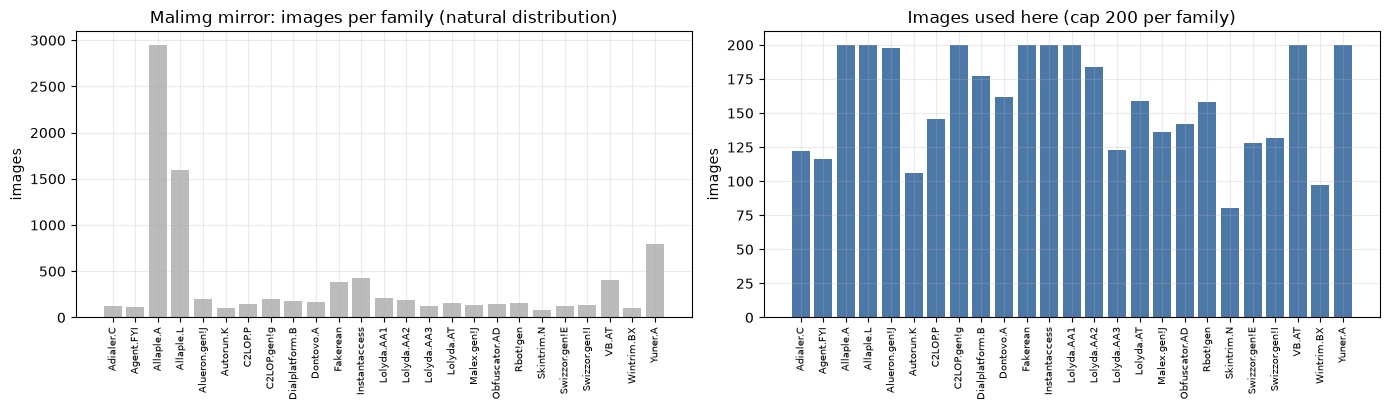

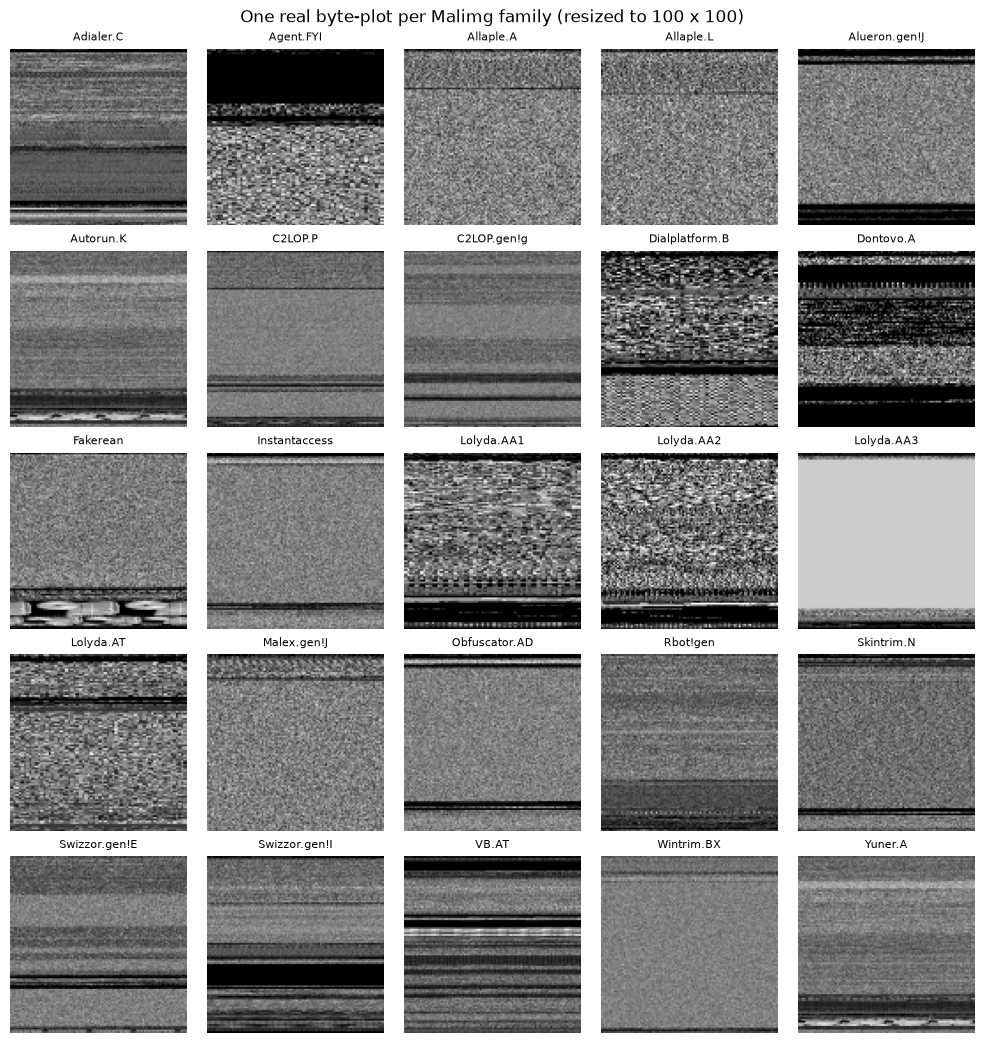

In [7]:
# ---- class distribution (bar chart) and one real example per family ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(range(N_CLS), cnt["in_mirror"], color="#BBBBBB"); ax[0].set_title("Malimg mirror: images per family (natural distribution)")
ax[1].bar(range(N_CLS), cnt["used"], color="#4C78A8"); ax[1].set_title(f"Images used here (cap {MAX_PER_FAMILY} per family)")
for a in ax:
    a.set_xticks(range(N_CLS)); a.set_xticklabels(CLASSES, rotation=90, fontsize=7); a.set_ylabel("images")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(5, 5, figsize=(10, 10.6))
for i, a in enumerate(axes.ravel()):
    j = np.where(y == i)[0][0]; a.imshow(X100[j], cmap="gray", vmin=0, vmax=255); a.set_title(CLASSES[i], fontsize=8); a.axis("off")
plt.suptitle("One real byte-plot per Malimg family (resized to 100 x 100)"); plt.tight_layout(); plt.show()

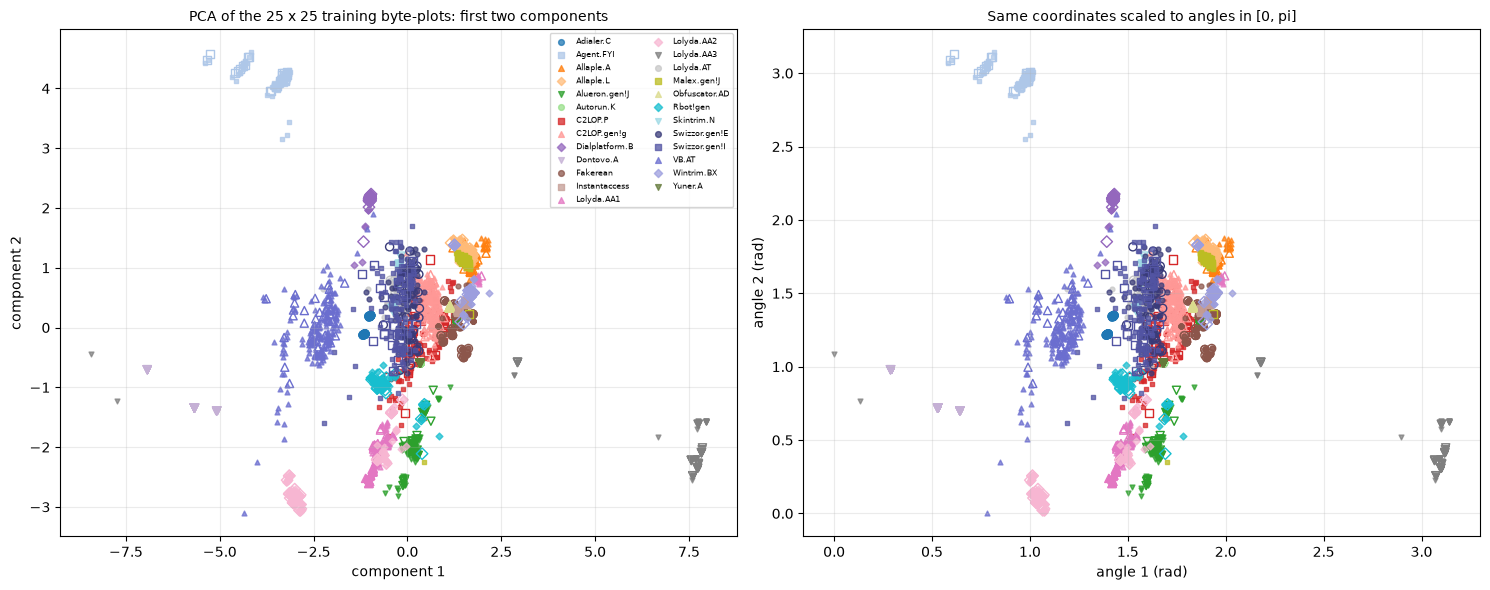

explained variance of the 2 components: 0.58  (filled = training, hollow = test images)


In [8]:
# ---- 2-D scatter of real observations coloured by ground-truth family (PCA fitted on the training split only) ----
Xf = X25.reshape(len(X25), -1)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xf[tr0])
P_tr, P_te = pca2.transform(Xf[tr0]), pca2.transform(Xf[te0])
mm = MinMaxScaler((0, np.pi)).fit(P_tr)                         # the same [0, pi] scaling an angle encoding would use
A_tr, A_te = mm.transform(P_tr), np.clip(mm.transform(P_te), 0, np.pi)
cols = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors[:5]); marks = ["o", "s", "^", "D", "v"]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, (T, V, ttl, ang) in zip(ax, ((P_tr, P_te, "PCA of the 25 x 25 training byte-plots: first two components", False),
                                    (A_tr, A_te, "Same coordinates scaled to angles in [0, pi]", True))):
    for i in range(N_CLS):
        m = y[tr0] == i; a.scatter(T[m, 0], T[m, 1], s=12, alpha=0.75, color=cols[i], marker=marks[i % 5], label=CLASSES[i])
        m = y[te0] == i; a.scatter(V[m, 0], V[m, 1], s=34, facecolors="none", edgecolors=cols[i], linewidths=1.0, marker=marks[i % 5])
    a.set_title(ttl, fontsize=10); a.set_xlabel("angle 1 (rad)" if ang else "component 1"); a.set_ylabel("angle 2 (rad)" if ang else "component 2")
ax[0].legend(fontsize=6, ncol=2, loc="best", markerscale=1.2)
plt.tight_layout(); plt.show()
print(f"explained variance of the 2 components: {pca2.explained_variance_ratio_.sum():.2f}  (filled = training, hollow = test images)")

## Quantum Circuit Architecture

**What the paper specifies.** Pixels `x` in [0,1] become angles `alpha = pi x`; `RY(alpha_i)` prepares one qubit per pixel; a quantum convolution kernel `U(theta)` acts on **windows** (`l = (m-1)^2` convolutions for an `m x m` image,
i.e. 576 for the 25 x 25 images, which is the number of 2 x 2 windows at stride 1); a pooling unit transfers the result to one qubit; Z expectation values are fed to a classical fully connected layer.
Several kernels give several feature maps. The paper gives **no gate-level definition** of `U(theta)` or of the pooling unit.

**What was chosen (every item is an assumption).**
* One circuit evaluation per 2 x 2 window, **4 qubits** (top-left, top-right, bottom-left, bottom-right pixel). Encoding `RY(pi x)`.
* Convolution `U(theta)`: `RY`, `RZ` on every qubit, then a ring of four CNOTs. The same angles are used for all 576 windows (weight sharing, like a convolution kernel).
* Pooling (QCNN style, Cong et al.): controlled-`RZ`, `X`, controlled-`RX` from qubit 0 to 1 and from 2 to 3 (4 -> 2 qubits), a second small convolution on qubits (1, 3) (`RY`, `RZ`, CNOT), and a second pooling 1 -> 3 (2 -> 1 qubit).
* Read-out: `<Z>` of qubit 3. So each kernel has **18 trainable angles** and produces one number per window.
* The whole circuit is one unitary followed by a Z measurement, so for a fixed set of angles the 16 x 16 matrix `U` is built once per batch and applied to all windows at once (exact state-vector simulation in PyTorch, differentiable). The **real PennyLane `QNode` below is the reference**; an assertion
  proves that the fast simulator and the `QNode` agree.

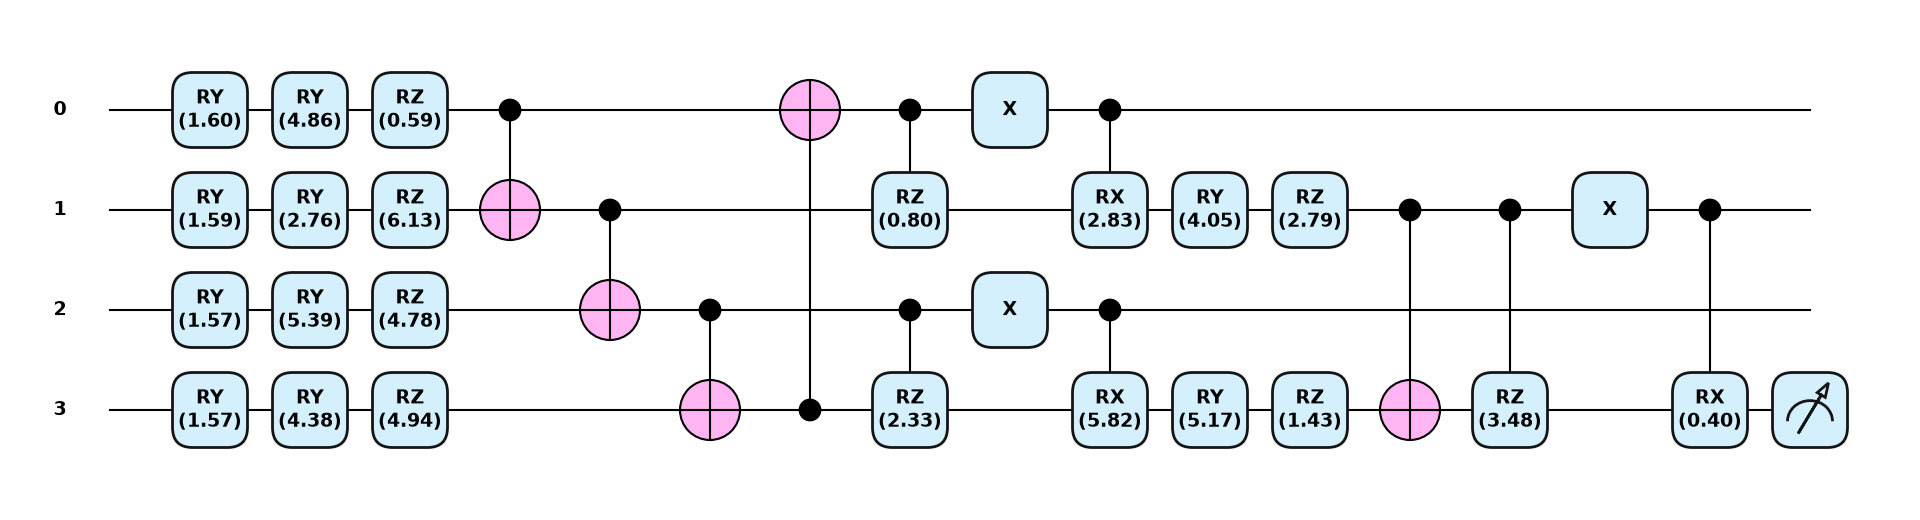

In [9]:
N_QUBITS = 4
N_PARAMS = 18
# One gate list = the circuit. Entries: (gate, wires, index into theta or None).
KERNEL = [
    *[("RY", (j,), j) for j in range(4)],                 # quantum convolution U(theta): single-qubit rotations ...
    *[("RZ", (j,), 4 + j) for j in range(4)],
    ("CNOT", (0, 1), None), ("CNOT", (1, 2), None), ("CNOT", (2, 3), None), ("CNOT", (3, 0), None),   # ... and an entangling ring
    ("CRZ", (0, 1), 8), ("X", (0,), None), ("CRX", (0, 1), 9),       # pooling 1: qubit 0 -> 1
    ("CRZ", (2, 3), 10), ("X", (2,), None), ("CRX", (2, 3), 11),     # pooling 1: qubit 2 -> 3
    ("RY", (1,), 12), ("RY", (3,), 13), ("RZ", (1,), 14), ("RZ", (3,), 15), ("CNOT", (1, 3), None),   # second convolution on the two survivors
    ("CRZ", (1, 3), 16), ("X", (1,), None), ("CRX", (1, 3), 17),     # pooling 2: qubit 1 -> 3
]
assert max(p for _, _, p in KERNEL if p is not None) + 1 == N_PARAMS
PL_GATE = {"RY": qml.RY, "RZ": qml.RZ, "CRZ": qml.CRZ, "CRX": qml.CRX, "CNOT": qml.CNOT, "X": qml.PauliX}
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="numpy")
def qconv_qnode(x, theta):
    """x: four pixel values in [0,1] (leading batch dimensions are broadcast by PennyLane); theta: 18 angles."""
    for j in range(4):
        qml.RY(np.pi * x[..., j], wires=j)               # angle encoding alpha = pi x  (paper)
    for name, w, p in KERNEL:
        wires = list(w) if len(w) > 1 else w[0]
        PL_GATE[name](wires=wires) if p is None else PL_GATE[name](theta[p], wires=wires)
    return qml.expval(qml.PauliZ(3))                     # Z-basis read-out (paper)

x_demo = X25[tr0[0]][10:12, 10:12].reshape(4)            # a real 2 x 2 window of a real training image
theta_demo = np.random.default_rng(SEED).uniform(0, 2 * np.pi, N_PARAMS)
fig, ax = qml.draw_mpl(qconv_qnode, decimals=2, style="pennylane")(x_demo, theta_demo)
plt.show()

qubits                      : 4
circuit depth               : 16
gate counts                 : {'RY': 10, 'RZ': 6, 'CNOT': 5, 'CRZ': 3, 'PauliX': 3, 'CRX': 3}
trainable angles per kernel : 18 | with N_KERNELS = 4: 72 quantum parameters
circuit evaluations / image : 576 windows x 4 kernels = 2304


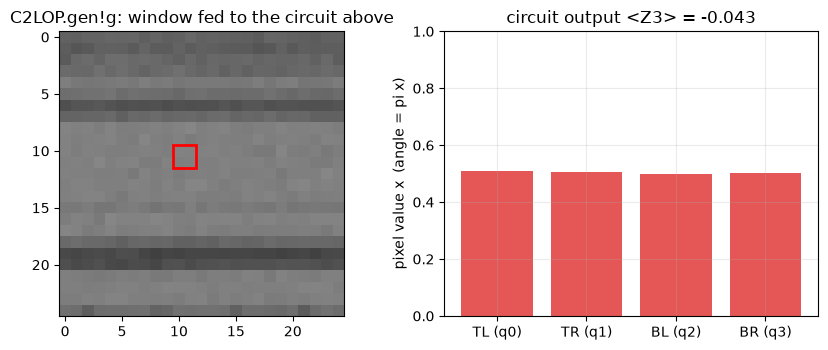

In [10]:
# ---- circuit facts (read from the executed QNode) ----
sp = qml.specs(qconv_qnode)(x_demo, theta_demo)
res = sp["resources"] if isinstance(sp, dict) else sp.resources
print("qubits                      :", N_QUBITS)
print("circuit depth               :", res.depth)
print("gate counts                 :", dict(res.gate_types))
print("trainable angles per kernel :", N_PARAMS, f"| with N_KERNELS = {N_KERNELS}: {N_KERNELS * N_PARAMS} quantum parameters")
print("circuit evaluations / image :", (IMG_Q - 1) ** 2, "windows x", N_KERNELS, "kernels =", (IMG_Q - 1) ** 2 * N_KERNELS)

# the real window used above, shown on its image
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.6))
ax[0].imshow(X25[tr0[0]], cmap="gray", vmin=0, vmax=1); ax[0].add_patch(plt.Rectangle((9.5, 9.5), 2, 2, fill=False, ec="red", lw=2))
ax[0].set_title(f"{CLASSES[y[tr0[0]]]}: window fed to the circuit above"); ax[0].grid(False)
ax[1].bar(["TL (q0)", "TR (q1)", "BL (q2)", "BR (q3)"], x_demo, color="#E45756"); ax[1].set_ylim(0, 1); ax[1].set_ylabel("pixel value x  (angle = pi x)")
ax[1].set_title(f"circuit output <Z3> = {float(qconv_qnode(x_demo, theta_demo)):+.3f}")
plt.tight_layout(); plt.show()

In [11]:
# ---- exact differentiable PyTorch simulator of the SAME gate list, and its equivalence to the PennyLane QNode ----
def _g1(name, a):
    if name == "X":
        return torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128)
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    if name == "RY":
        return torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
    e = torch.exp(-0.5j * a)                              # RZ
    return torch.diag(torch.stack([e, e.conj()]))

def _g2(name, a):
    if name == "CNOT":
        return torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=torch.complex128)
    if name == "CRZ":
        base = _g1("RZ", a)
    else:                                                 # CRX
        c, s = torch.cos(a / 2), torch.sin(a / 2)
        base = torch.stack([torch.stack([c + 0j, -1j * s]), torch.stack([-1j * s, c + 0j])])
    G = torch.zeros(4, 4, dtype=torch.complex128); G[:2, :2] = torch.eye(2); G = G.clone(); G[2:, 2:] = base
    return G

def circuit_unitary(theta):
    """16 x 16 unitary of the whole kernel circuit (wire 0 = most significant bit, as in PennyLane)."""
    S = torch.eye(16, dtype=torch.complex128).reshape(16, 2, 2, 2, 2)       # row b = U |b>
    for name, w, p in KERNEL:
        a = None if p is None else theta[p]
        if len(w) == 1:
            ax = 1 + w[0]; S = torch.movedim(torch.movedim(S, ax, -1) @ _g1(name, a).T, -1, ax)
        else:
            a1, a2 = 1 + w[0], 1 + w[1]
            S = torch.movedim(S, (a1, a2), (-2, -1)); sh = S.shape
            S = (S.reshape(*sh[:-2], 4) @ _g2(name, a).T).reshape(sh); S = torch.movedim(S, (-2, -1), (a1, a2))
    return S.reshape(16, 16).T

_Z3 = torch.tensor([1.0, -1.0], dtype=torch.float64).repeat(8)               # <Z> on qubit 3 = least significant bit

def window_states(x):
    """x: (..., 4) pixel values in [0,1] -> (..., 16) real amplitudes of RY(pi x_0) (x) ... (x) RY(pi x_3) |0000>."""
    ry = torch.stack([torch.cos(np.pi * x / 2), torch.sin(np.pi * x / 2)], -1)
    psi = torch.einsum("...a,...b,...c,...d->...abcd", ry[..., 0, :], ry[..., 1, :], ry[..., 2, :], ry[..., 3, :])
    return psi.reshape(*x.shape[:-1], 16)

def observable_matrix(theta):
    """Re(U^dagger Z_3 U): the Heisenberg-picture read-out. The input state is real, so <Z_3> = psi^T Re(U^dagger Z_3 U) psi exactly."""
    U = circuit_unitary(theta); Ur, Ui = U.real, U.imag
    return Ur.T @ (_Z3[:, None] * Ur) + Ui.T @ (_Z3[:, None] * Ui)

def qconv_features(x, theta):
    """x: (..., 4) pixel values in [0,1]; theta: (18,) float64.  Returns <Z3> for every window."""
    psi = window_states(x)
    return ((psi @ observable_matrix(theta)) * psi).sum(-1)
# equivalence: random inputs, random angles, and real windows of real training images
r = np.random.default_rng(1)
windows_real = np.stack([X25[i][a:a + 2, b:b + 2].reshape(4) for i, (a, b) in zip(tr0[:60], r.integers(0, 24, (60, 2)))])
worst = 0.0
for trial in range(5):
    th = r.uniform(0, 2 * np.pi, N_PARAMS)
    xs = np.concatenate([r.random((100, 4)), windows_real]).astype(np.float64)
    ref = qconv_qnode(xs, th)                                     # real PennyLane QNode (default.qubit)
    mine = qconv_features(torch.tensor(xs), torch.tensor(th)).numpy()
    worst = max(worst, float(np.abs(ref - mine).max()))
assert worst < 1e-10, worst
print(f"fast PyTorch simulator == PennyLane QNode on 5 x 160 inputs: max |difference| = {worst:.2e}  (assertion passed)")

fast PyTorch simulator == PennyLane QNode on 5 x 160 inputs: max |difference| = 8.33e-16  (assertion passed)


## 2. Training and evaluation helpers

One generic training loop (Adam, cross-entropy, batch 32 as in the paper's Table 3) is used for every network, and one function computes the paper's metrics: accuracy, precision, recall, F1 (weighted over families; macro shown too) and the one-vs-rest AUC.

In [12]:
RESULTS, PREDS, HIST = [], {}, {}

def metrics(yt, proba):
    pred = proba.argmax(1)
    pw, rw, fw, _ = precision_recall_fscore_support(yt, pred, average="weighted", zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(yt, pred, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(yt, proba, multi_class="ovr", average="macro", labels=np.arange(N_CLS))
    except ValueError:
        auc = np.nan
    return dict(acc=100 * accuracy_score(yt, pred), prec=100 * pw, rec=100 * rw, f1=100 * fw,
                prec_macro=100 * pm, rec_macro=100 * rm, f1_macro=100 * fm, auc=100 * auc)

def record(model, seed, yt, proba, secs, n_params, note=""):
    m = metrics(yt, proba); m.update(model=model, seed=seed, secs=secs, n_params=n_params, note=note)
    RESULTS.append(m); PREDS[(model, seed)] = (yt, proba)
    print(f"  {model:34s} seed {seed}: acc {m['acc']:.2f}  P {m['prec']:.2f}  R {m['rec']:.2f}  F1 {m['f1']:.2f}  AUC {m['auc']:.2f}  | {secs:.0f} s")

def fit(model, Xtr, ytr, epochs, lr, seed, prep=None, lr_theta=None, batch=BATCH):
    """Adam + cross-entropy.  Returns per-epoch mean loss and seconds."""
    gq = [p for n, p in model.named_parameters() if n.startswith("theta")]
    gh = [p for n, p in model.named_parameters() if not n.startswith("theta")]
    opt = torch.optim.Adam([{"params": gh, "lr": lr}] + ([{"params": gq, "lr": lr_theta}] if gq else []))
    g = torch.Generator().manual_seed(seed); n = len(ytr); hist = []; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, generator=g); tot = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i + batch]; xb = Xtr[idx]; xb = prep(xb) if prep else xb
            loss = F.cross_entropy(model(xb), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        hist.append(tot / n)
    return hist, time.time() - t0

@torch.no_grad()
def predict_proba(model, X, prep=None, bs=256):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]; out.append(F.softmax(model(prep(xb) if prep else xb), 1))
    return torch.cat(out).numpy()

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_head(d_in, hidden=128, p=0.3):
    return nn.Sequential(nn.Flatten(), nn.Linear(d_in, hidden), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden, N_CLS))

T100 = torch.from_numpy(X100)                       # uint8 (N, 100, 100)
T25 = torch.from_numpy(X25)                         # float32 (N, 25, 25)
Ty = torch.from_numpy(y).long()
prep100 = lambda b: b.float().div(255).unsqueeze(1)
print("helpers ready")

helpers ready


## 3. The paper's classical models

**Standard CNN** (100 x 100, trained from scratch, 25 epochs): three convolution blocks and a dense head. **VGG16** and **ResNet** (transfer learning): the ImageNet convolutional network is **frozen** and used as a feature extractor
(the paper does not say whether the backbone was fine-tuned); the grey-scale byte-plot is repeated over three channels and normalised with the ImageNet mean and standard deviation. Features are computed **once** for all images (they do not depend on the split) and a small dense head is trained on top for the
paper's number of epochs. Features are standardised with a scaler fitted on the training part only.

In [13]:
class StdCNN(nn.Module):
    def __init__(self, size):
        super().__init__()
        stem = nn.Sequential(nn.Conv2d(1, 16, 5, stride=2 if size >= 64 else 1, padding=2), nn.ReLU(), nn.MaxPool2d(2))   # CHOICE: strided stem keeps 100 x 100 affordable on a CPU
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.net = nn.Sequential(stem, blk(16, 32), blk(32, 64), nn.AdaptiveAvgPool2d(4), make_head(64 * 16))              # CHOICE: architecture
    def forward(self, x): return self.net(x)
seeds_cnn = SEEDS[:N_SEEDS_CNN100]
print("Standard CNN (100 x 100), epochs", EPOCHS_CNN)
for s in seeds_cnn:
    tr, te = SPLITS[s]; torch.manual_seed(s)
    m = StdCNN(IMG_C)
    h, secs = fit(m, T100[tr], Ty[tr], EPOCHS_CNN, LR_HEAD, s, prep=prep100)
    t0 = time.time(); pr = predict_proba(m, T100[te], prep=prep100); secs += time.time() - t0
    record("Standard CNN (100x100)", s, y[te], pr, secs, n_params(m)); HIST[("Standard CNN (100x100)", s)] = h

Standard CNN (100 x 100), epochs 25


  Standard CNN (100x100)             seed 42: acc 93.83  P 92.74  R 93.83  F1 92.84  AUC 99.89  | 480 s


In [14]:
# ---- frozen ImageNet backbones: features of every image, computed once and cached ----
tvm = torchvision.models
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def extract(name):
    f = os.path.join(DATA_DIR, f"feat_{name}_{IMG_C}_cap{MAX_PER_FAMILY}_seed{SEED}.npy")
    if os.path.exists(f):
        return np.load(f)
    if name == "vgg16":
        net = tvm.vgg16(weights=tvm.VGG16_Weights.IMAGENET1K_V1).features           # 13 convolution layers; 100 x 100 -> 512 x 3 x 3
    elif name == "resnet18":
        net = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1); net.fc = nn.Identity()
    else:
        net = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V1); net.fc = nn.Identity()
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(T100), 64):
            xb = T100[i:i + 64].float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
            out.append(net((xb - MEAN) / STD).flatten(1).numpy())
    F_ = np.concatenate(out).astype(np.float32); np.save(f, F_)
    return F_

t0 = time.time(); FEAT_VGG = extract("vgg16"); print("VGG16 features", FEAT_VGG.shape, f"({time.time() - t0:.0f} s)")
t0 = time.time(); FEAT_RES = extract(RESNET_NAME); print(RESNET_NAME, "features", FEAT_RES.shape, f"({time.time() - t0:.0f} s)")

VGG16 features (3966, 4608) (1079 s)


resnet18 features (3966, 512) (287 s)


In [15]:
def run_transfer(label, FEAT, epochs):
    print(f"{label} (frozen ImageNet backbone + dense head), epochs {epochs}")
    for s in SEEDS:
        tr, te = SPLITS[s]; torch.manual_seed(s)
        sc = StandardScaler().fit(FEAT[tr])                                           # fitted on the training split only
        Ftr, Fte = torch.from_numpy(sc.transform(FEAT[tr]).astype(np.float32)), torch.from_numpy(sc.transform(FEAT[te]).astype(np.float32))
        m = make_head(FEAT.shape[1])
        h, secs = fit(m, Ftr, Ty[tr], epochs, LR_HEAD, s)
        t0 = time.time(); pr = predict_proba(m, Fte); secs += time.time() - t0
        record(label, s, y[te], pr, secs, n_params(m)); HIST[(label, s)] = h

run_transfer("VGG16 (transfer)", FEAT_VGG, EPOCHS_VGG)
run_transfer("ResNet (transfer)", FEAT_RES, EPOCHS_RES)

VGG16 (transfer) (frozen ImageNet backbone + dense head), epochs 25


  VGG16 (transfer)                   seed 42: acc 95.97  P 95.98  R 95.97  F1 95.94  AUC 99.67  | 67 s


  VGG16 (transfer)                   seed 43: acc 95.09  P 95.23  R 95.09  F1 95.13  AUC 99.79  | 72 s


  VGG16 (transfer)                   seed 44: acc 92.82  P 91.05  R 92.82  F1 91.71  AUC 99.66  | 69 s
ResNet (transfer) (frozen ImageNet backbone + dense head), epochs 50


  ResNet (transfer)                  seed 42: acc 96.22  P 96.66  R 96.22  F1 96.31  AUC 99.91  | 28 s


  ResNet (transfer)                  seed 43: acc 96.35  P 96.28  R 96.35  F1 96.25  AUC 99.80  | 30 s


  ResNet (transfer)                  seed 44: acc 95.09  P 95.31  R 95.09  F1 94.90  AUC 99.85  | 33 s


## 4. The hybrid quantum-classical CNN (HQCCNN)

Input: the 25 x 25 image. A 2 x 2 window slides over it with stride 1 (576 positions). For each of the `N_KERNELS` quantum kernels the circuit of the previous section returns one `<Z>` per position, so the quantum convolution-pooling layer outputs `576 x N_KERNELS` numbers in [-1, 1].
They go into a classical fully connected head (dense 128, ReLU, dropout, dense 25). The 18 angles of each kernel and the head are trained together with Adam through the exact simulator (gradients by back-propagation through the state vector, which is what the PyTorch interface of PennyLane does on `default.qubit` as well).

**Controls trained on identical inputs** (the 25 x 25 images):
* *Classical 2 x 2 convolution + the same head*: the quantum layer is replaced by `Conv2d(1, N_KERNELS, 2)` + `tanh`, the same number of feature maps and the same head; this isolates what the quantum layer itself contributes.
* *Standard CNN on 25 x 25*: the same CNN as in Section 3 on the same small image (the paper compares its 25 x 25 hybrid with 100 x 100 classical networks, which mixes two effects).
* *Random forest* and *RBF-SVM* on the 625 raw pixels (and on the VGG16 features).

In [16]:
class HybridQCNN(nn.Module):
    """quantum convolution + pooling layer (N_KERNELS circuits shared over all 2x2 windows) -> classical fully connected head"""
    def __init__(self, n_kernels, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.theta = nn.Parameter(torch.rand(n_kernels, N_PARAMS, generator=g, dtype=torch.float64) * 2 * np.pi)   # CHOICE: uniform [0, 2 pi)
        self.n_windows = (IMG_Q - 1) ** 2
        self.head = make_head(self.n_windows * n_kernels)
    def qfeatures(self, x):                                   # x (B, 25, 25) float32 in [0, 1]
        w = x.unfold(1, 2, 1).unfold(2, 2, 1).reshape(len(x), self.n_windows, 4).double()      # window pixels in the order TL, TR, BL, BR
        psi = window_states(w)                                                                   # (B, 576, 16), shared by all kernels
        return torch.stack([((psi @ observable_matrix(self.theta[k])) * psi).sum(-1) for k in range(len(self.theta))], -1).float()   # (B, 576, K)
    def forward(self, x): return self.head(self.qfeatures(x))

class ClassicalConvControl(nn.Module):
    def __init__(self, n_kernels):
        super().__init__()
        self.conv = nn.Conv2d(1, n_kernels, 2); self.head = make_head((IMG_Q - 1) ** 2 * n_kernels)
    def forward(self, x): return self.head(torch.tanh(self.conv(x.unsqueeze(1))))

print("Hybrid QCNN (25 x 25, simulator), epochs", EPOCHS_Q, "| classical controls on the same input")
QMODELS = {}
for s in SEEDS:
    tr, te = SPLITS[s]
    torch.manual_seed(s); m = HybridQCNN(N_KERNELS, s)
    h, secs = fit(m, T25[tr], Ty[tr], EPOCHS_Q, LR_HEAD, s, lr_theta=LR_THETA)
    t0 = time.time(); pr = predict_proba(m, T25[te]); secs += time.time() - t0
    record("Hybrid QCNN (25x25)", s, y[te], pr, secs, n_params(m)); HIST[("Hybrid QCNN (25x25)", s)] = h; QMODELS[s] = m

    torch.manual_seed(s); c = ClassicalConvControl(N_KERNELS)
    h, secs = fit(c, T25[tr], Ty[tr], EPOCHS_Q, LR_HEAD, s)
    t0 = time.time(); pr = predict_proba(c, T25[te]); secs += time.time() - t0
    record("Classical 2x2 conv + same head (25x25)", s, y[te], pr, secs, n_params(c)); HIST[("Classical 2x2 conv + same head (25x25)", s)] = h

    torch.manual_seed(s); c = StdCNN(IMG_Q)
    h, secs = fit(c, T25[tr], Ty[tr], EPOCHS_Q, LR_HEAD, s, prep=lambda b: b.unsqueeze(1))
    t0 = time.time(); pr = predict_proba(c, T25[te], prep=lambda b: b.unsqueeze(1)); secs += time.time() - t0
    record("Standard CNN (25x25)", s, y[te], pr, secs, n_params(c)); HIST[("Standard CNN (25x25)", s)] = h
print("quantum parameters:", N_KERNELS * N_PARAMS, "| trainable parameters, hybrid model:", n_params(QMODELS[SEED]),
      "| classical control:", [r["n_params"] for r in RESULTS if r["model"].startswith("Classical 2x2")][0])

Hybrid QCNN (25 x 25, simulator), epochs 20 | classical controls on the same input


  Hybrid QCNN (25x25)                seed 42: acc 94.46  P 92.96  R 94.46  F1 93.48  AUC 99.90  | 681 s


  Classical 2x2 conv + same head (25x25) seed 42: acc 90.68  P 89.38  R 90.68  F1 89.13  AUC 99.45  | 57 s


  Standard CNN (25x25)               seed 42: acc 93.70  P 92.16  R 93.70  F1 92.69  AUC 99.86  | 261 s


  Hybrid QCNN (25x25)                seed 43: acc 94.46  P 92.85  R 94.46  F1 93.32  AUC 99.90  | 936 s


  Classical 2x2 conv + same head (25x25) seed 43: acc 92.32  P 90.36  R 92.32  F1 91.10  AUC 99.75  | 74 s


  Standard CNN (25x25)               seed 43: acc 91.94  P 90.79  R 91.94  F1 90.78  AUC 99.46  | 232 s


  Hybrid QCNN (25x25)                seed 44: acc 94.84  P 93.25  R 94.84  F1 93.71  AUC 99.93  | 725 s


  Classical 2x2 conv + same head (25x25) seed 44: acc 91.44  P 89.86  R 91.44  F1 90.36  AUC 99.79  | 57 s


  Standard CNN (25x25)               seed 44: acc 88.41  P 84.80  R 88.41  F1 85.87  AUC 99.87  | 251 s
quantum parameters: 72 | trainable parameters, hybrid model: 298337 | classical control: 298285


In [17]:
# ---- classical machine-learning controls on identical inputs (pixels of the 25 x 25 image, and the VGG16 features) ----
def run_sk(label, make, Xall, scale):
    for s in SEEDS:
        tr, te = SPLITS[s]
        A, B = Xall[tr], Xall[te]
        if scale:
            sc = StandardScaler().fit(A); A, B = sc.transform(A), sc.transform(B)           # fitted on the training split only
        t0 = time.time(); clf = make(s).fit(A, y[tr])
        if hasattr(clf, "predict_proba"):
            pr = clf.predict_proba(B)
        else:                                                    # SVC: softmax of the one-vs-rest decision scores (only used for the AUC)
            d = clf.decision_function(B); e = np.exp(d - d.max(1, keepdims=True)); pr = e / e.sum(1, keepdims=True)
        full = np.zeros((len(B), N_CLS)); full[:, clf.classes_] = pr
        record(label, s, y[te], full, time.time() - t0, 0)

PIX25 = X25.reshape(len(X25), -1)
print("sklearn controls (inputs identical to those of the quantum / transfer models)")
run_sk("Random forest (25x25 pixels)", lambda s: RandomForestClassifier(n_estimators=N_TREES, n_jobs=N_THREADS, random_state=s), PIX25, False)
run_sk("SVC rbf (25x25 pixels)", lambda s: SVC(kernel="rbf", C=10, gamma="scale", decision_function_shape="ovr"), PIX25, True)
run_sk("Random forest (VGG16 features)", lambda s: RandomForestClassifier(n_estimators=N_TREES, n_jobs=N_THREADS, random_state=s), FEAT_VGG, False)
run_sk("SVC rbf (VGG16 features)", lambda s: SVC(kernel="rbf", C=10, gamma="scale", decision_function_shape="ovr"), FEAT_VGG, True)

sklearn controls (inputs identical to those of the quantum / transfer models)


  Random forest (25x25 pixels)       seed 42: acc 97.23  P 97.21  R 97.23  F1 97.18  AUC 99.85  | 64 s


  Random forest (25x25 pixels)       seed 43: acc 96.98  P 96.92  R 96.98  F1 96.82  AUC 99.88  | 55 s


  Random forest (25x25 pixels)       seed 44: acc 96.10  P 96.09  R 96.10  F1 95.88  AUC 99.86  | 54 s


  SVC rbf (25x25 pixels)             seed 42: acc 95.59  P 93.91  R 95.59  F1 94.56  AUC 99.83  | 9 s


...

  Random forest (VGG16 features)     seed 43: acc 93.83  P 93.61  R 93.83  F1 93.51  AUC 99.84  | 82 s


  Random forest (VGG16 features)     seed 44: acc 95.21  P 94.79  R 95.21  F1 94.79  AUC 99.84  | 69 s


  SVC rbf (VGG16 features)           seed 42: acc 91.94  P 94.08  R 91.94  F1 92.46  AUC 98.24  | 131 s


  SVC rbf (VGG16 features)           seed 43: acc 92.07  P 93.72  R 92.07  F1 92.41  AUC 98.40  | 127 s


  SVC rbf (VGG16 features)           seed 44: acc 92.95  P 93.94  R 92.95  F1 93.06  AUC 98.61  | 116 s


### 4b. The trained quantum layer, run on the real PennyLane QNode

Training used the fast exact simulator. To show that the trained model really is the circuit above, a batch of test images is pushed through the **PennyLane `QNode`** (all windows at once, broadcast) with the trained angles, and the resulting features, logits and predictions are compared with the simulator's.

In [18]:
m = QMODELS[SEED]; tr, te = SPLITS[SEED]; sub = te[:48 if FAST_MODE else 120]
xb = T25[sub]
with torch.no_grad():
    f_sim = m.qfeatures(xb).numpy()                                                    # (B, 576, K) from the fast simulator
    w = xb.unfold(1, 2, 1).unfold(2, 2, 1).reshape(len(sub), 576, 4).double().numpy()
    t0 = time.time()
    f_qn = np.stack([qconv_qnode(w.reshape(-1, 4), m.theta[k].detach().numpy()).reshape(len(sub), 576) for k in range(N_KERNELS)], -1).astype(np.float32)   # real PennyLane QNode
    t_qn = time.time() - t0
    m.eval(); lg_sim = m.head(torch.from_numpy(f_sim)).numpy(); lg_qn = m.head(torch.from_numpy(f_qn)).numpy()
assert np.abs(f_sim - f_qn).max() < 1e-5 and (lg_sim.argmax(1) == lg_qn.argmax(1)).all()
print(f"{len(sub)} test images x 576 windows x {N_KERNELS} kernels = {len(sub) * 576 * N_KERNELS} circuit evaluations on the PennyLane QNode in {t_qn:.1f} s")
print(f"max |feature difference| simulator vs QNode: {np.abs(f_sim - f_qn).max():.2e} | identical predictions: {(lg_sim.argmax(1) == lg_qn.argmax(1)).all()}"
      f" | accuracy on these images: {100 * (lg_qn.argmax(1) == y[sub]).mean():.1f} %")

120 test images x 576 windows x 4 kernels = 276480 circuit evaluations on the PennyLane QNode in 26.6 s
max |feature difference| simulator vs QNode: 9.09e-13 | identical predictions: True | accuracy on these images: 95.8 %


## 5. Results

All numbers are percentages on the held-out 20 % of the images (mean +- standard deviation over the independent splits; one split in `FAST_MODE`, where the std is shown as 0.00). The from-scratch 100 x 100 CNN is the most expensive model on a CPU and is trained on the first split only (`N_SEEDS_CNN100 = 1`), so its std is also shown as 0.00.

In [19]:
R = pd.DataFrame(RESULTS)
ORDER = ["Standard CNN (100x100)", "VGG16 (transfer)", "ResNet (transfer)", "Hybrid QCNN (25x25)",
         "Classical 2x2 conv + same head (25x25)", "Standard CNN (25x25)", "Random forest (25x25 pixels)", "SVC rbf (25x25 pixels)",
         "Random forest (VGG16 features)", "SVC rbf (VGG16 features)"]
agg = R.groupby("model").agg(**{f"{c}_{f}": (c, f) for c in ("acc", "prec", "rec", "f1", "f1_macro", "auc", "secs", "n_params") for f in ("mean", "std")}).fillna(0).loc[ORDER]
pm = lambda c: [f"{a:.2f} +- {b:.2f}" for a, b in zip(agg[f"{c}_mean"], agg[f"{c}_std"])]
table = pd.DataFrame({"Accuracy": pm("acc"), "Precision": pm("prec"), "Recall": pm("rec"), "F1": pm("f1"), "F1 (macro)": pm("f1_macro"), "AUC": pm("auc"),
                      "train+predict (s)": [f"{a:.0f}" for a in agg["secs_mean"]], "trainable params": agg["n_params_mean"].astype(int)}, index=ORDER)
print(f"{len(SEEDS)} split(s); {len(y)} images, test part about {int(len(y) * TEST_SIZE)}")
table

3 split(s); 3966 images, test part about 793


,Accuracy,Precision,Recall,F1,F1 (macro),AUC,train+predict (s),trainable params
Standard CNN (100x100),93.83 +- 0.00,92.74 +- 0.00,93.83 +- 0.00,92.84 +- 0.00,91.23 +- 0.00,99.89 +- 0.00,480,157977
VGG16 (transfer),94.63 +- 1.62,94.09 +- 2.66,94.63 +- 1.62,94.26 +- 2.25,93.38 +- 2.91,99.71 +- 0.07,69,593177
ResNet (transfer),95.89 +- 0.69,96.08 +- 0.70,95.89 +- 0.69,95.82 +- 0.80,95.46 +- 0.66,99.85 +- 0.06,30,68889
Hybrid QCNN (25x25),94.58 +- 0.22,93.02 +- 0.21,94.58 +- 0.22,93.51 +- 0.20,92.00 +- 0.21,99.91 +- 0.02,781,298337
Classical 2x2 conv + same head (25x25),91.48 +- 0.82,89.87 +- 0.49,91.48 +- 0.82,90.20 +- 1.00,88.40 +- 0.97,99.67 +- 0.19,63,298285
Standard CNN (25x25),91.35 +- 2.69,89.25 +- 3.92,91.35 +- 2.69,89.78 +- 3.52,88.19 +- 3.48,99.73 +- 0.23,248,157977
Random forest (25x25 pixels),96.77 +- 0.60,96.74 +- 0.58,96.77 +- 0.60,96.63 +- 0.67,96.22 +- 0.64,99.86 +- 0.02,58,0
SVC rbf (25x25 pixels),95.30 +- 0.32,93.60 +- 0.36,95.30 +- 0.32,94.23 +- 0.34,92.80 +- 0.42,99.74 +- 0.08,9,0
Random forest (VGG16 features),94.58 +- 0.70,94.28 +- 0.61,94.58 +- 0.70,94.24 +- 0.66,93.59 +- 0.59,99.84 +- 0.00,81,0
SVC rbf (VGG16 features),92.32 +- 0.55,93.91 +- 0.18,92.32 +- 0.55,92.64 +- 0.36,92.45 +- 0.33,98.42 +- 0.18,125,0


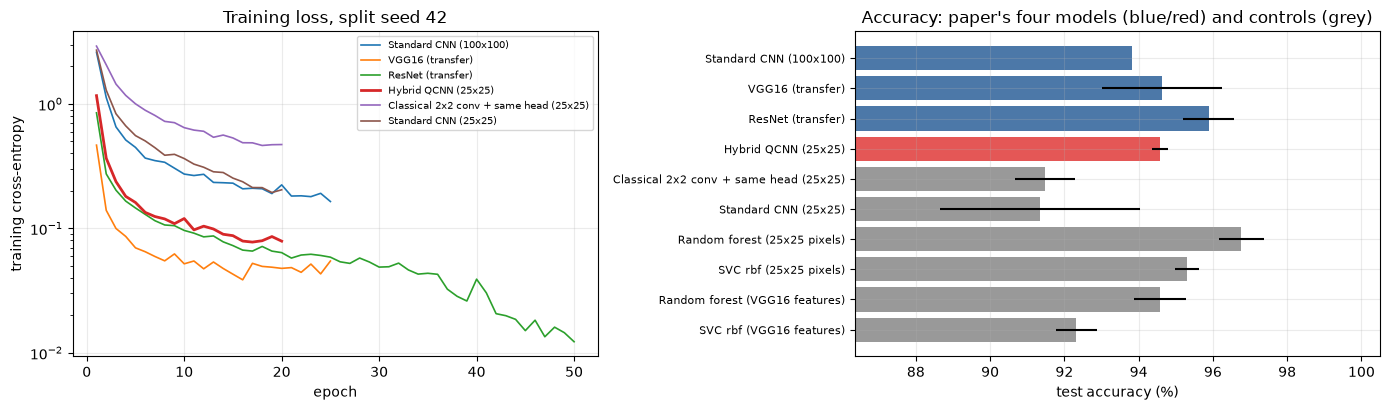

In [20]:
# ---- training curves and bar chart ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for (mdl, s), h in HIST.items():
    if s == SEED:
        ax[0].plot(range(1, len(h) + 1), h, label=mdl, lw=2 if mdl.startswith("Hybrid") else 1.2)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training cross-entropy"); ax[0].set_yscale("log"); ax[0].set_title(f"Training loss, split seed {SEED}"); ax[0].legend(fontsize=7)
ax[1].barh(range(len(ORDER)), agg["acc_mean"], xerr=agg["acc_std"], color=["#4C78A8"] * 3 + ["#E45756"] + ["#999999"] * 6)
ax[1].set_yticks(range(len(ORDER))); ax[1].set_yticklabels(ORDER, fontsize=8); ax[1].invert_yaxis(); ax[1].set_xlim(max(0, agg["acc_mean"].min() - 5), 100.5)
ax[1].set_xlabel("test accuracy (%)"); ax[1].set_title("Accuracy: paper's four models (blue/red) and controls (grey)")
plt.tight_layout(); plt.show()

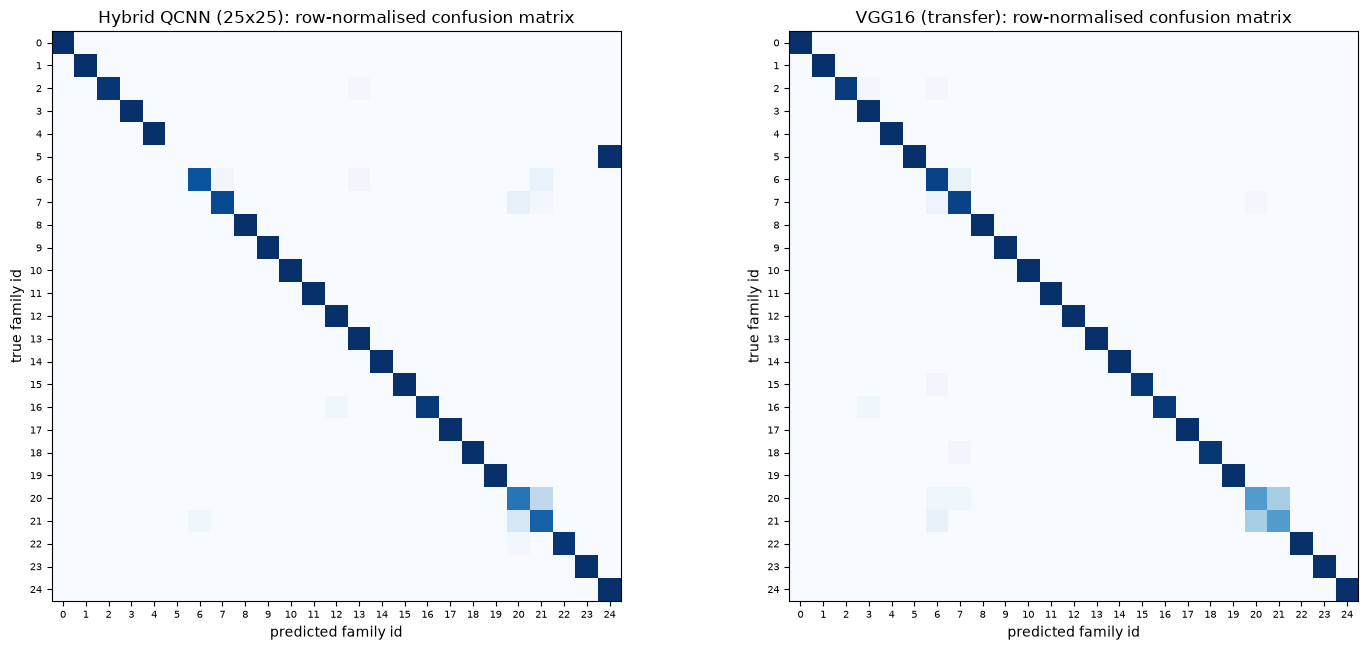

family ids: 0=Adialer.C, 1=Agent.FYI, 2=Allaple.A, 3=Allaple.L, 4=Alueron.gen!J, 5=Autorun.K, 6=C2LOP.P, 7=C2LOP.gen!g, 8=Dialplatform.B, 9=Dontovo.A, 10=Fakerean, 11=Instantaccess, 12=Lolyda.AA1, 13=Lolyda.AA2, 14=Lolyda.AA3, 15=Lolyda.AT, 16=Malex.gen!J, 17=Obfuscator.AD, 18=Rbot!gen, 19=Skintrim.N, 20=Swizzor.gen!E, 21=Swizzor.gen!I, 22=VB.AT, 23=Wintrim.BX, 24=Yuner.A

per-family F1 (split seed 42), the three weakest families of the hybrid model first:
               Hybrid QCNN (25x25)  VGG16 (transfer)  Standard CNN (100x100)  test images
Autorun.K                    0.000             1.000                   0.000           21
Swizzor.gen!E                0.717             0.588                   0.651           26
Swizzor.gen!I                0.737             0.600                   0.676           26
Yuner.A                      0.792             1.000                   0.792           40
C2LOP.P                      0.909             0.857                   0.808           29

In [21]:
# ---- confusion matrices (rows = true family, columns = predicted) for the hybrid QCNN and VGG16, split seed 42, and per-family F1 ----
fig, ax = plt.subplots(1, 2, figsize=(15, 6.6))
for a, mdl in zip(ax, ("Hybrid QCNN (25x25)", "VGG16 (transfer)")):
    yt, pr = PREDS[(mdl, SEED)]; cm = confusion_matrix(yt, pr.argmax(1), labels=range(N_CLS))
    im = a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); a.grid(False)
    a.set_xticks(range(N_CLS)); a.set_yticks(range(N_CLS)); a.set_xticklabels(range(N_CLS), fontsize=7); a.set_yticklabels(range(N_CLS), fontsize=7)
    a.set_xlabel("predicted family id"); a.set_ylabel("true family id"); a.set_title(f"{mdl}: row-normalised confusion matrix")
plt.tight_layout(); plt.show()
print("family ids:", ", ".join(f"{i}={c}" for i, c in enumerate(CLASSES)))
f1 = {mdl: precision_recall_fscore_support(PREDS[(mdl, SEED)][0], PREDS[(mdl, SEED)][1].argmax(1), labels=range(N_CLS), zero_division=0)[2]
      for mdl in ("Hybrid QCNN (25x25)", "VGG16 (transfer)", "Standard CNN (100x100)")}
pf = pd.DataFrame(f1, index=CLASSES).round(3); pf["test images"] = [int((PREDS[("VGG16 (transfer)", SEED)][0] == i).sum()) for i in range(N_CLS)]
print("\nper-family F1 (split seed 42), the three weakest families of the hybrid model first:")
print(pf.sort_values("Hybrid QCNN (25x25)").head(8).to_string())

## 6. Side by side with the paper (Table 4) and verdicts

Rule for the verdicts: a metric is **reproduced** when the notebook's mean is within 2 percentage points of the paper's value, **exceeded** / **not reached** when it is more than 2 points above / below. Statements about ranking use the means.
The paper's own F1 values look inconsistent with its precision and recall (for VGG16: P = 97.01, R = 96.85 but F1 = 97.49); this is flagged in the critical reading below.

In [22]:
PAPER = {  # Table 4 of the paper: accuracy, precision, recall, F1, AUC (percent)
    "Standard CNN (100x100)": (96.89, 96.99, 96.88, 96.99, 98.3), "VGG16 (transfer)": (97.32, 97.01, 96.85, 97.49, 98.3),
    "ResNet (transfer)": (96.99, 96.36, 95.99, 96.32, 97.99), "Hybrid QCNN (25x25)": (97.11, 97.01, 97.12, 97.56, 98.0)}
MET = ["acc", "prec", "rec", "f1", "auc"]; MET_NAME = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
rows = []
for mdl, vals in PAPER.items():
    for k, nm, pv in zip(MET, MET_NAME, vals):
        o = agg.loc[mdl, f"{k}_mean"]
        rows.append(dict(model=mdl, metric=nm, paper=pv, notebook=round(o, 2), std=round(agg.loc[mdl, f"{k}_std"], 2), diff=round(o - pv, 2), verdict=verdict(o, pv)))
cmp_df = pd.DataFrame(rows)
cmp_df

,model,metric,paper,notebook,std,diff,verdict
0,Standard CNN (100x100),Accuracy,96.89,93.83,0.00,-3.06,not reached
1,Standard CNN (100x100),Precision,96.99,92.74,0.00,-4.25,not reached
2,Standard CNN (100x100),Recall,96.88,93.83,0.00,-3.05,not reached
3,Standard CNN (100x100),F1,96.99,92.84,0.00,-4.15,not reached
4,Standard CNN (100x100),AUC,98.30,99.89,0.00,1.59,reproduced
5,VGG16 (transfer),Accuracy,97.32,94.63,1.62,-2.69,not reached
6,VGG16 (transfer),Precision,97.01,94.09,2.66,-2.92,not reached
7,VGG16 (transfer),Recall,96.85,94.63,1.62,-2.22,not reached
8,VGG16 (transfer),F1,97.49,94.26,2.25,-3.23,not reached
9,VGG16 (transfer),AUC,98.30,99.71,0.07,1.41,reproduced


In [23]:
# ---- narrative claims ----
A = agg["acc_mean"]
claims = []
claims.append(("VGG16 transfer learning is the best of the four models (accuracy)",
               "reproduced" if A[list(PAPER)].idxmax() == "VGG16 (transfer)" else "not reached", f"best of the four here: {A[list(PAPER)].idxmax()} ({A[list(PAPER)].max():.2f} %)"))
rank = A[list(PAPER)].sort_values(ascending=False).index.tolist()
claims.append(("The hybrid QCNN is second in accuracy, right behind VGG16 (97.11 vs 97.32)",
               "reproduced" if rank[:2] == ["VGG16 (transfer)", "Hybrid QCNN (25x25)"] else "not reached", "ranking here: " + " > ".join(rank)))
gap = A["VGG16 (transfer)"] - A["Hybrid QCNN (25x25)"]
claims.append(("The hybrid QCNN on 25 x 25 images is within 1 point of VGG16 on 100 x 100 (paper gap 0.21)",
               "reproduced" if abs(gap) <= 1.0 else "not reached", f"gap here {gap:+.2f} points"))
claims.append(("The hybrid model is comparable to the lighter standard CNN (paper: nearly identical)",
               "reproduced" if abs(A['Hybrid QCNN (25x25)'] - A['Standard CNN (100x100)']) <= 1.0 else "not reached",
               f"hybrid {A['Hybrid QCNN (25x25)']:.2f} vs CNN(100x100) {A['Standard CNN (100x100)']:.2f}; but standard CNN on the same 25x25 input: {A['Standard CNN (25x25)']:.2f}"))
claims.append(("(Our control, no paper claim) the quantum layer helps compared with a classical 2x2 convolution + same head",
               "yes" if A["Hybrid QCNN (25x25)"] - A["Classical 2x2 conv + same head (25x25)"] > 1.0 else ("no" if A["Hybrid QCNN (25x25)"] - A["Classical 2x2 conv + same head (25x25)"] < -1.0 else "no difference"),
               f"hybrid {A['Hybrid QCNN (25x25)']:.2f} vs classical conv {A['Classical 2x2 conv + same head (25x25)']:.2f}"))
claims.append(("Hybrid training is much slower than the classical models (paper: 7 h 43 min vs 3 to 6 min)", "cannot be checked",
               f"here: hybrid {agg.loc['Hybrid QCNN (25x25)', 'secs_mean']:.0f} s vs CNN {agg.loc['Standard CNN (100x100)', 'secs_mean']:.0f} s, VGG16 head {agg.loc['VGG16 (transfer)', 'secs_mean']:.0f} s "
               "(different simulator and hardware; VGG16/ResNet times here exclude the one-off feature extraction)"))
claims.append(("Quantum hardware / noise results", "cannot be checked", "the paper reports no hardware numbers; only simulator results are given"))
cl = pd.DataFrame(claims, columns=["claim", "verdict", "evidence in this run"])
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 250)
print(cmp_df.groupby("verdict").size().to_string(), "\n")
cl

verdict
not reached    12
reproduced      8 



,claim,verdict,evidence in this run
0,VGG16 transfer learning is the best of the four models (accuracy),not reached,best of the four here: ResNet (transfer) (95.89 %)
1,"The hybrid QCNN is second in accuracy, right behind VGG16 (97.11 vs 97.32)",not reached,ranking here: ResNet (transfer) > VGG16 (transfer) > Hybrid QCNN (25x25) > Standard CNN (100x100)
2,The hybrid QCNN on 25 x 25 images is within 1 point of VGG16 on 100 x 100 (paper gap 0.21),reproduced,gap here +0.04 points
3,The hybrid model is comparable to the lighter standard CNN (paper: nearly identical),reproduced,hybrid 94.58 vs CNN(100x100) 93.83; but standard CNN on the same 25x25 input: 91.35
4,"(Our control, no paper claim) the quantum layer helps compared with a classical 2x2 convolution + same head",yes,hybrid 94.58 vs classical conv 91.48
5,Hybrid training is much slower than the classical models (paper: 7 h 43 min vs 3 to 6 min),cannot be checked,"here: hybrid 781 s vs CNN 480 s, VGG16 head 69 s (different simulator and hardware; VGG16/ResNet times here exclude the one-off feature extraction)"
6,Quantum hardware / noise results,cannot be checked,the paper reports no hardware numbers; only simulator results are given


## 7. Reading the paper critically

* **What is measured.** Despite the title ("malware detection") the task is 25-way *family* classification of Malimg. Malimg is known to be easy: families have very distinctive byte-plot textures and many near-duplicate samples (variants of the same binary). All four models reach about 97 % in the paper; with that ceiling the differences of 0.1 to 0.4 points between models are well inside the split-to-split noise that the repeated splits above make visible. A ranking "VGG16 first, hybrid second" is therefore not statistically supported.
* **Unequal inputs.** The hybrid model sees 25 x 25 images, the others 100 x 100, and the paper presents the small image as an advantage of the hybrid model. The controls show whether it is the quantum layer or simply the task that makes 25 x 25 sufficient: compare the hybrid model with the *standard CNN on the same 25 x 25 images* and with the *classical 2 x 2 convolution + identical head*.
* **Metric inconsistencies.** For VGG16 the paper lists precision 97.01 and recall 96.85 but F1 97.49, and for the hybrid model 97.01 / 97.12 / 97.56. An F1 score that exceeds both averaged precision and recall by half a point is unusual (it can only arise through an unspecified averaging scheme); accuracy, precision and recall are mutually consistent, F1 is not. Table 3 gives 100 x 100 images for the classical networks while the text twice says 110 x 110.
* **"m x m qubits".** The text says an `m x m` image needs `m x m` qubits, which would be 625 qubits and cannot be simulated; but the count `(m-1)^2` of convolutions shows a sliding-window circuit. We implemented the sliding 2 x 2 window with 4 qubits; if the authors really used a different circuit (for example larger windows, or amplitude/angle encoding of the whole image), the results need not carry over.
* **The quantum layer is a fixed-size feature map.** With 4 qubits per window and 18 angles per kernel the quantum layer has 72 parameters; the classical head after it has several hundred thousand. Most of the learning capacity is classical. The classical-convolution control with the same head is the fair test of the "quantum advantage" wording; the paper does not include it.
* **Strength of the controls.** The classical-convolution control is deliberately minimal (a few linear 2 x 2 filters + tanh); a gap between it and the quantum layer shows the value of a richer non-linear window feature, not of quantum mechanics as such. Simple classical learners (RBF-SVM, random forest) on the 25 x 25 pixels are strong baselines on this data: compare them with every deep model in the results table before drawing conclusions.
* **Simulation cost vs claims.** The reported 7 h 43 min for 20 epochs is a property of a slow generic simulator loop (one circuit per window per image), not of the algorithm: because the whole circuit is one 16 x 16 unitary shared by all windows, the same model trains here in a few tens of seconds per epoch on a single, shared CPU thread (see the timing column). No quantum speed-up is shown or implied.
* **Transfer learning details.** Frozen vs fine-tuned backbones, ResNet depth (50 in the text), optimiser and learning rates are not stated. The natural Malimg class imbalance (the two Allaple families are about half of the data) makes accuracy a weak metric; weighted P / R / F1 hide small families. Per-family F1 above shows where each model fails.
* **Data.** The paper says 9,939 images (the public benchmark has 9,339) and gives no seed or split code, and random 80 / 20 splits of Malimg place near-duplicate variants of one family on both sides, which favours every model. No separate hold-out of unseen *variants* is used.

## 8. Exercises

1. **Split noise.** Increase `SEEDS` to ten values (and `FAST_MODE = False`). How large is the std of the hybrid model's accuracy compared with its gap to VGG16? Is the paper's ranking stable?
2. **Fair comparison of image size.** Re-run the classical networks on 25 x 25 images (`StdCNN(IMG_Q)` is already there) and the transfer models on 25 x 25 images upsampled to 100 x 100. Which of the paper's conclusions about image size survive?
3. **Circuit variants.** Remove the CNOT ring from `KERNEL` (a product circuit with no entanglement) and re-train. Does accuracy drop? Then replace the pooling gates by a plain `<Z>` of each qubit (4 features per window). What does that tell you about the role of the quantum pooling unit?
4. **More kernels / bigger windows.** Set `N_KERNELS` to 1, 2, 8 and plot accuracy against the number of quantum parameters. Then implement a 3 x 3 window (9 qubits, 512 amplitudes) and compare; the simulator code in `circuit_unitary` needs only a new `KERNEL` list and tensor shape.
5. **Natural class distribution.** Set `MAX_PER_FAMILY = None` (about 1.1 GB streamed once) so that the Allaple families dominate as in the paper. How do accuracy, weighted F1 and macro F1 change, and why does the weighted metric look better than the macro one?

In [24]:
print(f"total notebook run time: {(time.time() - _T_START) / 60:.1f} minutes  (FAST_MODE = {FAST_MODE})")

total notebook run time: 110.1 minutes  (FAST_MODE = False)
